Original Dataset:
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset Shape: (200, 5)
K = 2 Silhouette Score = 0.3213
K = 3 Silhouette Score = 0.4666
K = 4 Silhouette Score = 0.4939
K = 5 Silhouette Score = 0.5547
K = 6 Silhouette Score = 0.5399
K = 7 Silhouette Score = 0.5281
K = 8 Silhouette Score = 0.4552
K = 9 Silhouette Score = 0.4571
K = 10 Silhouette Score = 0.4432

Optimal Number of Clusters: 5

Clustered Dataset:
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                 

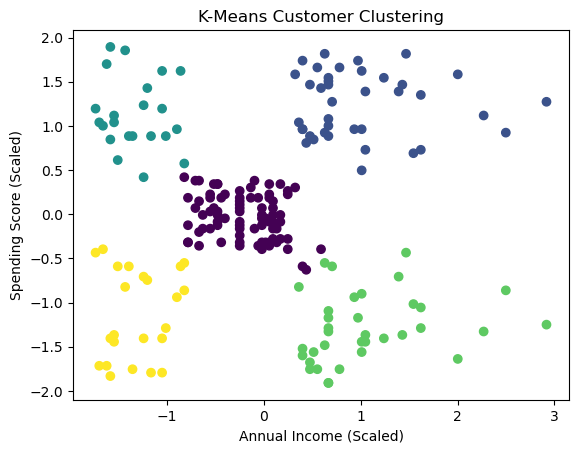

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv(r"C:\Users\Tanuja\Downloads\Mall_Customers.csv")

print("Original Dataset:")
print(df.head())
print("\nDataset Shape:", df.shape)

X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scores = {}

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)
    print("K =", k, "Silhouette Score =", round(scores[k], 4))

optimal_k = max(scores, key=scores.get)

print("\nOptimal Number of Clusters:", optimal_k)

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("\nClustered Dataset:")
print(df.head())

print("\nCustomers in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())

plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=df["Cluster"], cmap="viridis")
plt.xlabel("Annual Income (Scaled)")
plt.ylabel("Spending Score (Scaled)")
plt.title("K-Means Customer Clustering")
plt.show()

In [ ]:
%pip install pandas matplotlib scikit-learn
# PRACTICAL 8: K-MEANS CLUSTERING

## 1. Aim

To apply the K-Means clustering algorithm on a suitable open-access dataset and determine the optimal number of clusters using the Silhouette Method.

## 2. Dataset Used

**Dataset Name:** Mall Customers Dataset  
**File Name:** `Mall_Customers.csv`  
**Total Records:** 200  
**Total Columns:** 5

The dataset contains the following attributes:

| Attribute | Description |
|---|---|
| CustomerID | Unique customer identification number |
| Genre | Gender of the customer |
| Age | Age of the customer |
| Annual Income (k$) | Annual income in thousands of dollars |
| Spending Score (1-100) | Customer spending behaviour score |

**Features selected for clustering:**

1. Annual Income (k$)
2. Spending Score (1-100)

These two features are selected because they help identify customer groups based on income and spending behaviour.

## 3. Theory

### What is Clustering?

Clustering is an unsupervised machine learning technique used to divide a dataset into different groups called clusters.

Data points within the same cluster have similar characteristics, whereas data points belonging to different clusters have comparatively different characteristics.

Clustering does not require predefined output labels. It discovers patterns and groups automatically from the input data.

**Example:** A shopping mall can group customers based on their annual income and spending score. This helps the mall understand customer behaviour and plan suitable marketing strategies.

### What is K-Means Clustering?

K-Means is an unsupervised machine learning algorithm used to divide a dataset into K different clusters.

Here, K represents the number of clusters. Each cluster has a centre point called a centroid.

The algorithm assigns each data point to the nearest centroid and repeatedly updates the centroid positions until the clusters become stable or the stopping condition is reached.

### Working of K-Means Algorithm

1. Select the number of clusters K.
2. Initialize K centroids randomly.
3. Calculate the distance between each data point and the centroids.
4. Assign each data point to its nearest centroid.
5. Calculate new centroids using the mean of the data points in each cluster.
6. Repeat the assignment and centroid calculation steps.
7. Stop when the centroids no longer change significantly or the maximum number of iterations is reached.

### Mathematical Formula

**1. Euclidean Distance**

K-Means commonly uses Euclidean distance to calculate the distance between a data point and a centroid.

d = √[(x₁ − c₁)² + (x₂ − c₂)² + ... + (xₙ − cₙ)²]

Where:

- x represents the data point.
- c represents the centroid.
- n represents the number of features.

**2. Centroid Calculation**

The centroid is calculated by taking the mean of all data points assigned to a cluster.

New Centroid = Sum of data points in the cluster / Number of data points in the cluster.

### What is the Silhouette Method?

The Silhouette Method is used to evaluate the quality of clustering and help determine the optimal number of clusters.

It measures how well a data point fits into its assigned cluster compared with other clusters.

The Silhouette Score ranges from -1 to +1.

- **Close to +1:** The data point is well matched to its own cluster and separated from other clusters.
- **Around 0:** The data point may lie near the boundary between two clusters.
- **Close to -1:** The data point may have been assigned to the wrong cluster.

**Silhouette Score Formula:**

s = (b − a) / max(a, b)

Where:

- a = Average distance between a data point and other points in its own cluster.
- b = Minimum average distance between that data point and points in another cluster.

A higher Silhouette Score generally indicates better-separated and more compact clusters.

In this practical, different values of K from 2 to 10 are tested. The value of K with the highest Silhouette Score is selected as the optimal number of clusters.

### Importance of Feature Scaling

Feature scaling is used to bring numerical features to a comparable scale.

K-Means uses distance calculations. If one feature has a much larger numerical range than another, it can dominate the distance calculation.

StandardScaler transforms the data using:

z = (x − μ) / σ

Where:

- x = Original feature value.
- μ = Mean of the feature.
- σ = Standard deviation of the feature.
- z = Standardized value.

After scaling, each feature has approximately zero mean and unit variance.

## 4. Algorithm

1. Import the required Python libraries.
2. Set the OMP_NUM_THREADS environment variable to avoid the Windows MKL warning.
3. Load the Mall Customers dataset.
4. Display the first five records and dataset information.
5. Select Annual Income and Spending Score as input features.
6. Apply StandardScaler to scale the input features.
7. Initialize an empty dictionary to store Silhouette Scores.
8. Apply K-Means for different values of K from 2 to 10.
9. Calculate the Silhouette Score for each clustering result.
10. Select the K value with the highest Silhouette Score.
11. Apply the final K-Means model using the optimal K.
12. Add cluster labels to the original dataset.
13. Display the clustered dataset and number of customers in each cluster.
14. Visualize the clusters using a scatter plot.

## 5. Python Program

### Installation command

Run this command only if the required libraries are not installed:

```python
%pip install pandas matplotlib scikit-learn
```

### Main program

```python
import os
os.environ["OMP_NUM_THREADS"] = "1"

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv(r"C:\Users\Tanuja\Downloads\Mall_Customers.csv")

print("Original Dataset:")
print(df.head())
print("\nDataset Shape:", df.shape)

X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scores = {}

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)
    print("K =", k, "Silhouette Score =", round(scores[k], 4))

optimal_k = max(scores, key=scores.get)

print("\nOptimal Number of Clusters:", optimal_k)

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("\nClustered Dataset:")
print(df.head())

print("\nCustomers in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())

plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=df["Cluster"], cmap="viridis")

plt.xlabel("Annual Income (Scaled)")
plt.ylabel("Spending Score (Scaled)")
plt.title("K-Means Customer Clustering")
plt.show()
```

## 6. Line-by-Line Explanation of the Program

### A. Importing libraries

**Line 1:**
```python
import os
```
Imports the OS module, which allows Python to access and modify environment variables.

**Line 2:**
```python
os.environ["OMP_NUM_THREADS"] = "1"
```
Sets the number of OpenMP threads to 1. This helps avoid the Windows MKL memory-leak warning reported by Scikit-learn in this environment.

This line should execute before importing Scikit-learn and its numerical dependencies.

**Line 3:**
```python
import pandas as pd
```
Imports the Pandas library with the alias `pd`. It is used to load and manipulate the dataset.

**Line 4:**
```python
import matplotlib.pyplot as plt
```
Imports Matplotlib's plotting module with the alias `plt`. It is used to visualize the clusters.

**Line 5:**
```python
from sklearn.preprocessing import StandardScaler
```
Imports StandardScaler from Scikit-learn. It is used to standardize the numerical features.

**Line 6:**
```python
from sklearn.cluster import KMeans
```
Imports the KMeans algorithm from Scikit-learn. It is used to create clusters.

**Line 7:**
```python
from sklearn.metrics import silhouette_score
```
Imports the Silhouette Score function. It is used to evaluate the quality of the clusters.

### B. Loading the dataset

**Line 8:**
```python
df = pd.read_csv(r"C:\Users\Tanuja\Downloads\Mall_Customers.csv")
```
Loads the Mall Customers CSV file into a Pandas DataFrame named `df`.

The letter `r` before the file path creates a raw string, which allows Windows backslashes to be used safely.

**Line 9:**
```python
print("Original Dataset:")
```
Displays a heading before showing the dataset.

**Line 10:**
```python
print(df.head())
```
Displays the first five rows of the dataset.

**Line 11:**
```python
print("\nDataset Shape:", df.shape)
```
Displays the shape of the dataset.

The `shape` attribute returns the number of rows and columns. In your dataset, the shape is `(200, 5)`.

### C. Selecting input features

**Line 12:**
```python
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
```
Selects two numerical columns from the dataset.

- Annual Income represents the customer's annual income.
- Spending Score represents the customer's shopping behaviour score.

The selected columns are stored in variable `X`.

CustomerID, Genre and Age are not used in this practical's clustering model.

### D. Feature scaling

**Line 13:**
```python
scaler = StandardScaler()
```
Creates an object of the StandardScaler class.

**Line 14:**
```python
X_scaled = scaler.fit_transform(X)
```
Calculates the mean and standard deviation of each feature and transforms the values into a standardized scale.

This is important because K-Means uses distance calculations.

### E. Calculating Silhouette Scores

**Line 15:**
```python
scores = {}
```
Creates an empty dictionary named `scores` to store the Silhouette Score for each value of K.

**Line 16:**
```python
for k in range(2, 11):
```
Starts a loop that tests different numbers of clusters, from 2 to 10.

The `range(2, 11)` function includes 2 but excludes 11.

**Line 17:**
```python
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
```
Creates a K-Means model for the current value of K.

- `n_clusters=k` specifies the number of clusters.
- `random_state=42` makes the random initialization reproducible.
- `n_init=10` runs K-Means with 10 different centroid initializations and selects the result with the lowest inertia.

**Line 18:**
```python
labels = kmeans.fit_predict(X_scaled)
```
Trains the K-Means model using scaled data and assigns a cluster label to every data point.

The generated labels are stored in the variable `labels`.

**Line 19:**
```python
scores[k] = silhouette_score(X_scaled, labels)
```
Calculates the Silhouette Score for the current clustering result and stores it in the dictionary using K as the key.

**Line 20:**
```python
print("K =", k, "Silhouette Score =", round(scores[k], 4))
```
Displays the number of clusters and its Silhouette Score.

The `round()` function displays the score up to four decimal places.

### F. Finding the optimal number of clusters

**Line 21:**
```python
optimal_k = max(scores, key=scores.get)
```
Finds the key K whose stored Silhouette Score is the highest.

This value is selected as the optimal number of clusters among the tested values.

**Line 22:**
```python
print("\nOptimal Number of Clusters:", optimal_k)
```
Displays the selected optimal number of clusters.

### G. Applying final K-Means clustering

**Line 23:**
```python
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
```
Creates a new K-Means model using the optimal number of clusters.

**Line 24:**
```python
df["Cluster"] = kmeans.fit_predict(X_scaled)
```
Trains the final model, assigns each customer to a cluster and adds the resulting cluster labels as a new column named `Cluster` in the original dataset.

### H. Displaying the results

**Line 25:**
```python
print("\nClustered Dataset:")
```
Displays a heading for the clustered dataset.

**Line 26:**
```python
print(df.head())
```
Displays the first five dataset records along with their newly assigned cluster labels.

**Line 27:**
```python
print("\nCustomers in Each Cluster:")
```
Displays a heading before showing the number of customers in each cluster.

**Line 28:**
```python
print(df["Cluster"].value_counts().sort_index())
```
Counts the customers in each cluster and sorts the cluster labels in ascending order.

### I. Visualizing the clusters

**Line 29–30:**
```python
plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=df["Cluster"], cmap="viridis")
```
Creates a scatter plot of the clustered data.

- `X_scaled[:, 0]` selects the first feature, Annual Income.
- `X_scaled[:, 1]` selects the second feature, Spending Score.
- `c=df["Cluster"]` assigns colours according to cluster labels.
- `cmap="viridis"` selects the colour map used to display clusters.

**Line 31:**
```python
plt.xlabel("Annual Income (Scaled)")
```
Sets the label of the X-axis.

**Line 32:**
```python
plt.ylabel("Spending Score (Scaled)")
```
Sets the label of the Y-axis.

**Line 33:**
```python
plt.title("K-Means Customer Clustering")
```
Sets the title of the scatter plot.

**Line 34:**
```python
plt.show()
```
Displays the final cluster visualization.

## 7. Actual Output from Execution

The program successfully loaded 200 customer records and tested K values from 2 to 10.

| Number of clusters (K) | Silhouette Score |
|---:|---:|
| 2 | 0.3213 |
| 3 | 0.4666 |
| 4 | 0.4939 |
| 5 | **0.5547** |
| 6 | 0.5399 |
| 7 | 0.5281 |
| 8 | 0.4552 |
| 9 | 0.4571 |
| 10 | 0.4432 |

**Optimal Number of Clusters: 5**

**Customers in Each Cluster:**

| Cluster | Number of Customers |
|---:|---:|
| 0 | 81 |
| 1 | 39 |
| 2 | 22 |
| 3 | 35 |
| 4 | 23 |
| **Total** | **200** |

The highest Silhouette Score is 0.5547 for K = 5. Therefore, five clusters are selected from the tested values.

## 8. Important Viva Questions and Answers

**Q1. What is clustering?**

Clustering is an unsupervised machine learning technique used to group similar data points together.

**Q2. What is K-Means clustering?**

K-Means is an unsupervised algorithm that divides data into K clusters based on the distance between data points and cluster centroids.

**Q3. What is the meaning of K in K-Means?**

K represents the number of clusters to be created.

**Q4. What is a centroid?**

A centroid is the centre point of a cluster, calculated using the mean of the data points assigned to that cluster.

**Q5. Is K-Means supervised or unsupervised?**

K-Means is an unsupervised learning algorithm because it does not require predefined class labels.

**Q6. What is the Silhouette Method?**

It is a method used to evaluate clustering quality and determine a suitable number of clusters.

**Q7. What is the range of Silhouette Score?**

The range is from -1 to +1.

**Q8. What does a high Silhouette Score indicate?**

It generally indicates that clusters are compact and well separated from one another.

**Q9. Why is feature scaling required?**

K-Means uses distance calculations. Feature scaling prevents features with larger numerical ranges from dominating the clustering process.

**Q10. Why is StandardScaler used?**

It transforms features to approximately zero mean and unit variance.

**Q11. Why is K started from 2 in the program?**

Silhouette Score requires at least two clusters because it compares a data point's own cluster with another cluster.

**Q12. Why do we use random_state=42?**

It controls random initialization and helps make the results reproducible.

**Q13. What is the purpose of n_init=10?**

It performs 10 different initializations of K-Means and selects the result with the lowest inertia.

**Q14. What is the purpose of fit_predict()?**

It trains the clustering model and returns the cluster label assigned to each data point.

**Q15. Why is CustomerID not used?**

CustomerID is only an identification number and does not represent meaningful customer behaviour.

## 9. Advanced External Viva Questions

**Q1. Can K-Means work without knowing the number of clusters in advance?**

The K-Means algorithm requires a K value to be supplied. Methods such as the Elbow Method and Silhouette Method can help estimate a suitable value.

**Q2. Why does the Silhouette Score start from K = 2?**

With only one cluster, there is no second cluster to compare against. Therefore, the Silhouette Score cannot be calculated meaningfully.

**Q3. Can the highest Silhouette Score always be considered the best clustering?**

It is the best score among the tested K values, but the final choice should also consider the dataset, practical requirements and interpretability.

**Q4. Can Elbow Method and Silhouette Method give different results?**

Yes. The Elbow Method evaluates the reduction in inertia, whereas the Silhouette Method evaluates cluster cohesion and separation. They can suggest different values of K.

**Q5. What happens if K is too large?**

The dataset may be divided into too many small clusters, making the grouping difficult to interpret.

**Q6. What are the limitations of K-Means?**

- The number of clusters must be selected in advance.
- It is sensitive to initial centroid positions.
- It is affected by outliers.
- It may perform poorly on irregularly shaped clusters.
- It can struggle when clusters have very different sizes or densities.

**Q7. Why are only two features used in this practical?**

Annual Income and Spending Score are useful for customer segmentation and allow the clusters to be visualized in a two-dimensional scatter plot.

**Q8. Are cluster labels 0, 1, 2, 3 and 4 fixed customer categories?**

No. They are numerical identifiers assigned by the algorithm. The cluster numbers do not have fixed meanings and can change between different runs or initializations.

## 10. Dataset-Specific Viva Questions

**Q1. Why is the Mall Customers dataset suitable for this practical?**

It contains customer information that can be used to identify groups with similar income and spending behaviour.

**Q2. What is the meaning of Annual Income (k$)?**

It represents the customer's annual income in thousands of dollars.

**Q3. What is Spending Score?**

It is a score assigned to customers based on their shopping behaviour. In this dataset, it ranges from 1 to 100.

**Q4. Why is Genre not used in this implementation?**

This implementation uses two numerical features for distance-based clustering and two-dimensional visualization. Genre is categorical and is not needed for this particular analysis.

**Q5. What is the use of customer segmentation?**

It helps businesses understand customer groups and develop targeted marketing strategies.

## 11. Important Points to Remember

- Algorithm: K-Means Clustering.
- Learning type: Unsupervised Learning.
- Dataset: Mall Customers.
- Total records: 200.
- Selected features: Annual Income and Spending Score.
- Distance measure: Euclidean Distance.
- Scaling technique: StandardScaler.
- Cluster evaluation: Silhouette Method.
- Tested K values: 2 to 10.
- Optimal K from this execution: 5.
- Highest Silhouette Score: 0.5547.
- Final output: Five customer clusters.
- Python library: Scikit-learn.